# Lab 03 — Nhiệm vụ II.1: Thuật toán Canny bằng OpenCV và scikit-image

**Thành viên thực hiện (TV1):** Phụ trách Mục II.1  
**Mục tiêu bài thực hành:**
1. **Tìm hiểu & trực quan hóa các bước trung gian:** Ảnh xám $\rightarrow$ Khử nhiễu Gaussian $\rightarrow$ Đạo hàm Sobel $\rightarrow$ Độ lớn & hướng Gradient $\rightarrow$ Biên Canny.
2. **Khảo sát chuyên sâu các tham số trong `cv2.Canny`:**
   - Cặp ngưỡng kép (Double/Hysteresis Thresholds: `threshold1`, `threshold2`).
   - Kích thước khẩu độ Sobel (`apertureSize`: 3, 5, 7).
   - Cách tính độ lớn Gradient (`L2gradient`: $L_1$ norm vs $L_2$ norm).
3. **Thực hiện Canny bằng `scikit-image` (`skimage.feature.canny`):**
   - Áp dụng trên cùng tập ảnh kiểm thử.
   - Khảo sát ảnh hưởng của tham số `sigma`, `low_threshold`, `high_threshold`.
4. **So sánh trực quan & Đánh giá phân tích:**
   - So sánh trực tiếp kết quả, cấu trúc đầu ra, độ mỏng của biên và thời gian thực thi giữa OpenCV và scikit-image.
   - Lưu trữ toàn bộ biểu đồ và kết quả vào thư mục `result/figures/` và `data/output/`.

---

In [1]:
import os
import sys
import time
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
from skimage.feature import canny

# Cấu hình hiển thị Matplotlib
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# 1. Cấu hình đường dẫn linh hoạt (hỗ trợ chạy từ root repository hoặc thư mục lab_2/notebook)
cwd = Path.cwd().resolve()
if (cwd / "data" / "input").exists():
    LAB2_DIR = cwd
elif (cwd / "lab_2" / "data" / "input").exists():
    LAB2_DIR = cwd / "lab_2"
elif (cwd.parent / "data" / "input").exists():
    LAB2_DIR = cwd.parent
else:
    candidates = [p for p in [cwd] + list(cwd.parents) if (p / "lab_2" / "data" / "input").exists()]
    LAB2_DIR = candidates[0] / "lab_2" if candidates else cwd

INPUT_DIR = LAB2_DIR / "data" / "input"
OUTPUT_DIR = LAB2_DIR / "data" / "output"
FIGURES_DIR = LAB2_DIR / "result" / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Thư mục làm việc LAB2 : {LAB2_DIR.name}")
print(f"Thư mục ảnh đầu vào   : {INPUT_DIR} ({len(list(INPUT_DIR.glob('*.png')))} file PNG)")
print(f"Thư mục ảnh đầu ra    : {OUTPUT_DIR}")
print(f"Thư mục biểu đồ lưu   : {FIGURES_DIR}")
print(f"Phiên bản OpenCV      : {cv2.__version__}")
print(f"Phiên bản scikit-image: {skimage.__version__}")
print(f"Phiên bản NumPy       : {np.__version__}")

Thư mục làm việc LAB2 : lab_2
Thư mục ảnh đầu vào   : E:\XỬ LÍ THỊ GIÁC MÁY TÍNH\Computer-Vision-Group-2\lab_2\data\input (50 file PNG)
Thư mục ảnh đầu ra    : E:\XỬ LÍ THỊ GIÁC MÁY TÍNH\Computer-Vision-Group-2\lab_2\data\output
Thư mục biểu đồ lưu   : E:\XỬ LÍ THỊ GIÁC MÁY TÍNH\Computer-Vision-Group-2\lab_2\result\figures
Phiên bản OpenCV      : 5.0.0
Phiên bản scikit-image: 0.26.0
Phiên bản NumPy       : 2.3.4


In [2]:
def read_image_bgr(path):
    """Đọc ảnh bằng np.fromfile + cv2.imdecode để an toàn với đường dẫn tiếng Việt trên Windows."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Không thể giải mã ảnh: {path}")
    return img

def read_image_gray(path):
    """Đọc ảnh ở dạng ảnh xám (Grayscale)."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Không thể giải mã ảnh xám: {path}")
    return img

def save_image(path, img):
    """Lưu ảnh bằng cv2.imencode an toàn với đường dẫn tiếng Việt."""
    path = Path(path)
    ext = path.suffix if path.suffix else ".png"
    success, buffer = cv2.imencode(ext, img)
    if not success:
        raise OSError(f"Lỗi khi mã hóa ảnh để lưu: {path}")
    with open(path, "wb") as f:
        f.write(buffer)
    return True

print("-> Đã khởi tạo các hàm đọc/lưu ảnh an toàn.")

-> Đã khởi tạo các hàm đọc/lưu ảnh an toàn.


---
## 1. Tìm hiểu & Trực quan hóa các bước trung gian của thuật toán Canny

Thuật toán phát hiện biên Canny (John F. Canny, 1986) là một quy trình đa giai đoạn gồm 5 bước cốt lõi:
1. **Lọc mờ Gaussian (Noise Reduction):** Sử dụng bộ lọc Gaussian 2D để làm mịn ảnh và loại bỏ nhiễu tần số cao (vì đạo hàm rất nhạy với nhiễu).
2. **Tính Gradient (Gradient Calculation):** Dùng toán tử Sobel tính độ biến thiên cường độ sáng theo trục ngang $G_x$ và trục dọc $G_y$. Từ đó suy ra:
   - Độ lớn Gradient: $G = \sqrt{G_x^2 + G_y^2}$ (hoặc xấp xỉ $|G_x| + |G_y|$).
   - Hướng Gradient: $\theta = \arctan2(G_y, G_x)$ (quy về 4 hướng chính: $0^\circ, 45^\circ, 90^\circ, 135^\circ$).
3. **Non-Maximum Suppression (Làm mỏng biên):** Chỉ giữ lại các điểm có độ lớn gradient là cực đại địa phương dọc theo hướng gradient, loại bỏ các điểm lân cận để tạo đường biên mỏng 1 pixel.
4. **Ngưỡng kép (Double Thresholding):**
   - Điểm có $G \ge T_{high}$: Chắc chắn là biên (Strong Edge).
   - Điểm có $T_{low} \le G < T_{high}$: Biên yếu tiềm năng (Weak Edge).
   - Điểm có $G < T_{low}$: Nhiễu $\rightarrow$ Loại bỏ hoàn toàn.
5. **Nối biên bằng Hysteresis (Edge Tracking by Hysteresis):** Giữ lại các Weak Edge nếu chúng có liên kết 8 hướng với ít nhất một Strong Edge, ngược lại loại bỏ.

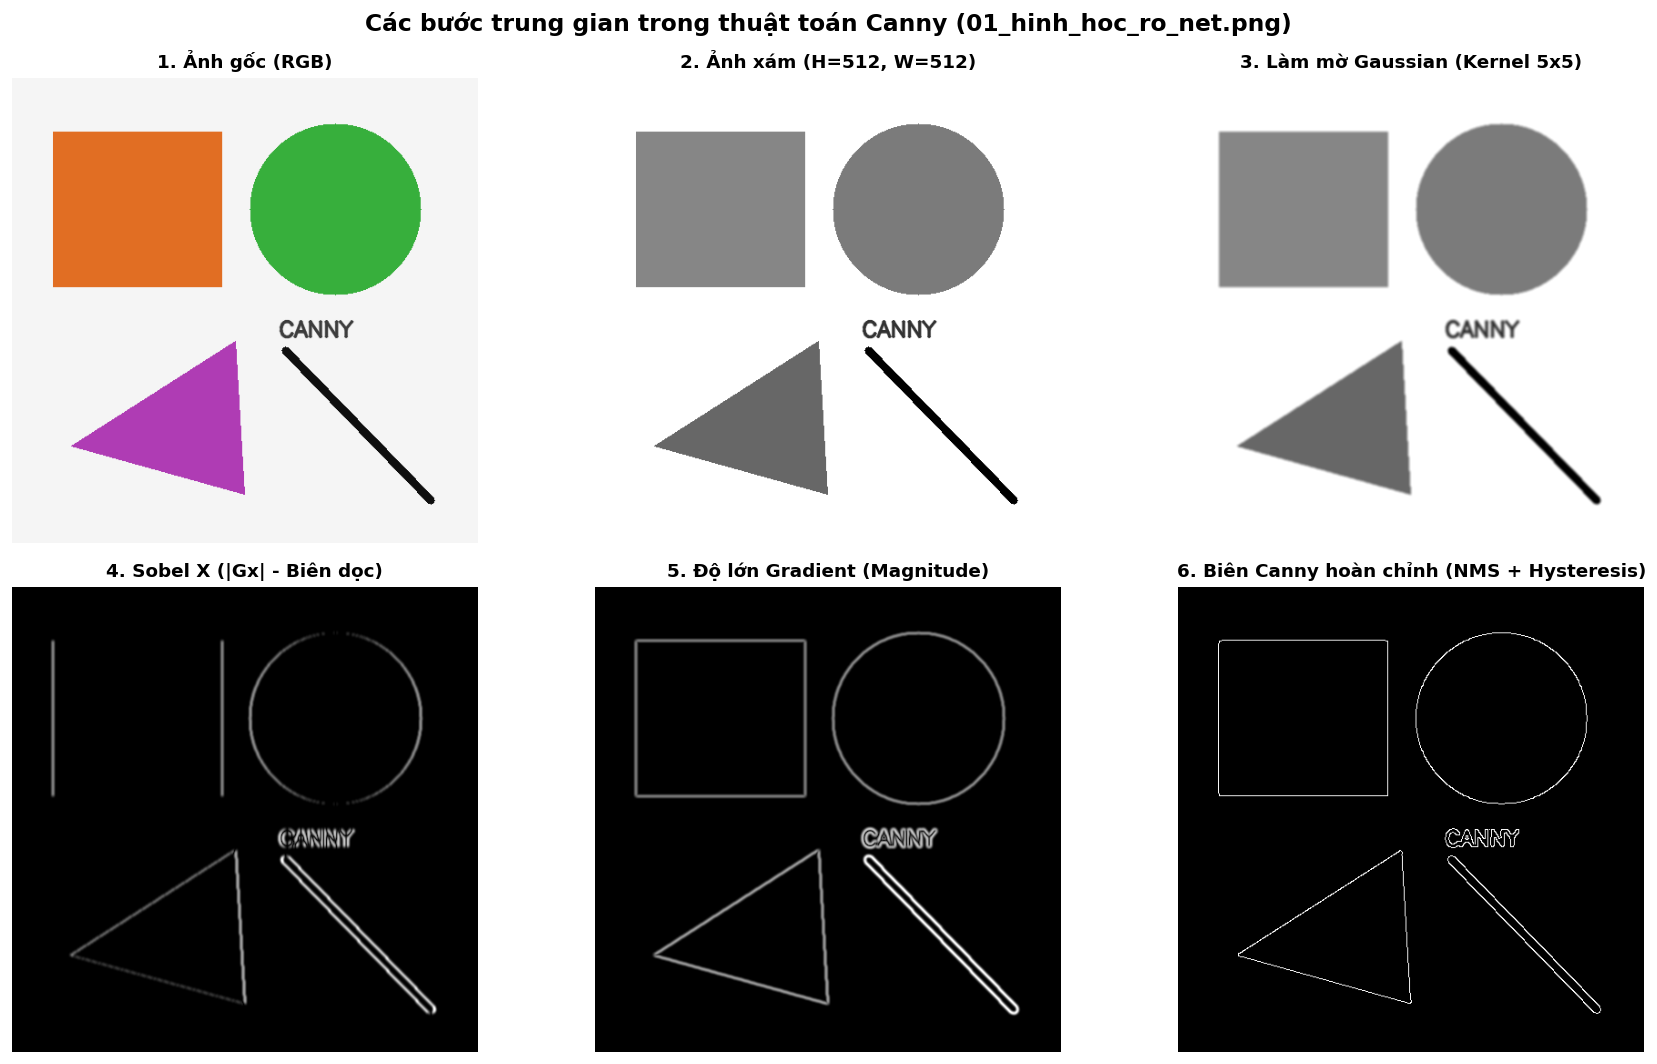

-> Đã xuất biểu đồ các bước trung gian: 01_canny_intermediate_stages.png


In [3]:
# Chọn ảnh hình học rõ nét từ tập input
sample_img_path = INPUT_DIR / "01_hinh_hoc_ro_net.png"
if not sample_img_path.exists():
    sample_img_path = list(INPUT_DIR.glob("*.png"))[0]

img_bgr = read_image_bgr(sample_img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Bước 1: Ảnh xám
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Bước 2: Làm mờ Gaussian (Kernel 5x5, sigma=1.4)
img_blur = cv2.GaussianBlur(img_gray, (5, 5), 1.4)

# Bước 3: Tính đạo hàm Sobel X và Sobel Y (cv2.CV_64F để giữ giá trị âm)
sobel_x = cv2.Sobel(img_blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_blur, cv2.CV_64F, 0, 1, ksize=3)

# Độ lớn Gradient (L2 norm) và chuẩn hóa về uint8 để hiển thị
gradient_mag = np.sqrt(sobel_x**2 + sobel_y**2)
gradient_mag_disp = np.uint8(255 * gradient_mag / (np.max(gradient_mag) + 1e-8))

# Bước 4 & 5: Kết quả Canny chuẩn từ OpenCV
canny_result = cv2.Canny(img_blur, threshold1=50, threshold2=150, apertureSize=3, L2gradient=True)

# Trực quan hóa toàn bộ chuỗi xử lý trung gian
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title("1. Ảnh gốc (RGB)", fontsize=11, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_gray, cmap='gray')
axes[0, 1].set_title(f"2. Ảnh xám (H={img_gray.shape[0]}, W={img_gray.shape[1]})", fontsize=11, fontweight='bold')
axes[0, 1].axis('off')

axes[0, 2].imshow(img_blur, cmap='gray')
axes[0, 2].set_title("3. Làm mờ Gaussian (Kernel 5x5)", fontsize=11, fontweight='bold')
axes[0, 2].axis('off')

axes[1, 0].imshow(np.abs(sobel_x), cmap='gray')
axes[1, 0].set_title("4. Sobel X (|Gx| - Biên dọc)", fontsize=11, fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(gradient_mag_disp, cmap='gray')
axes[1, 1].set_title("5. Độ lớn Gradient (Magnitude)", fontsize=11, fontweight='bold')
axes[1, 1].axis('off')

axes[1, 2].imshow(canny_result, cmap='gray')
axes[1, 2].set_title("6. Biên Canny hoàn chỉnh (NMS + Hysteresis)", fontsize=11, fontweight='bold')
axes[1, 2].axis('off')

plt.suptitle(f"Các bước trung gian trong thuật toán Canny ({sample_img_path.name})", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

# Lưu biểu đồ
fig_path_stages = FIGURES_DIR / "01_canny_intermediate_stages.png"
plt.savefig(fig_path_stages, bbox_inches='tight', dpi=150)
plt.show()

print(f"-> Đã xuất biểu đồ các bước trung gian: {fig_path_stages.name}")

---
## 2. Khảo sát chuyên sâu các tham số trong `cv2.Canny`

Hàm `cv2.Canny(image, threshold1, threshold2, apertureSize=3, L2gradient=False)` có 3 nhóm tham số cốt lõi:
1. **`threshold1` & `threshold2` (Ngưỡng dưới và ngưỡng trên):**
   - Tỷ lệ khuyến nghị thông thường giữa $T_{high} / T_{low}$ là $2:1$ hoặc $3:1$.
   - Nếu ngưỡng quá thấp: Xuất hiện nhiều cạnh giả do nhiễu kết cấu (texture noise).
   - Nếu ngưỡng quá cao: Các cạnh quan trọng bị đứt khúc hoặc biến mất.
2. **`apertureSize`:**
   - Kích thước cửa sổ tính đạo hàm Sobel (phải là số lẻ: 3, 5, 7).
   - Aperture lớn bắt các cạnh trên vùng rộng hơn nhưng dễ làm mờ vị trí chính xác của cạnh và tăng độ nhạy với nhiễu.
3. **`L2gradient`:**
   - `False` (mặc định): Dùng khoảng cách $L_1 = |G_x| + |G_y|$ (tính toán nhanh hơn).
   - `True`: Dùng khoảng cách Euclidean $L_2 = \sqrt{G_x^2 + G_y^2}$ (độ chính xác cao hơn, đúng hình học hơn).

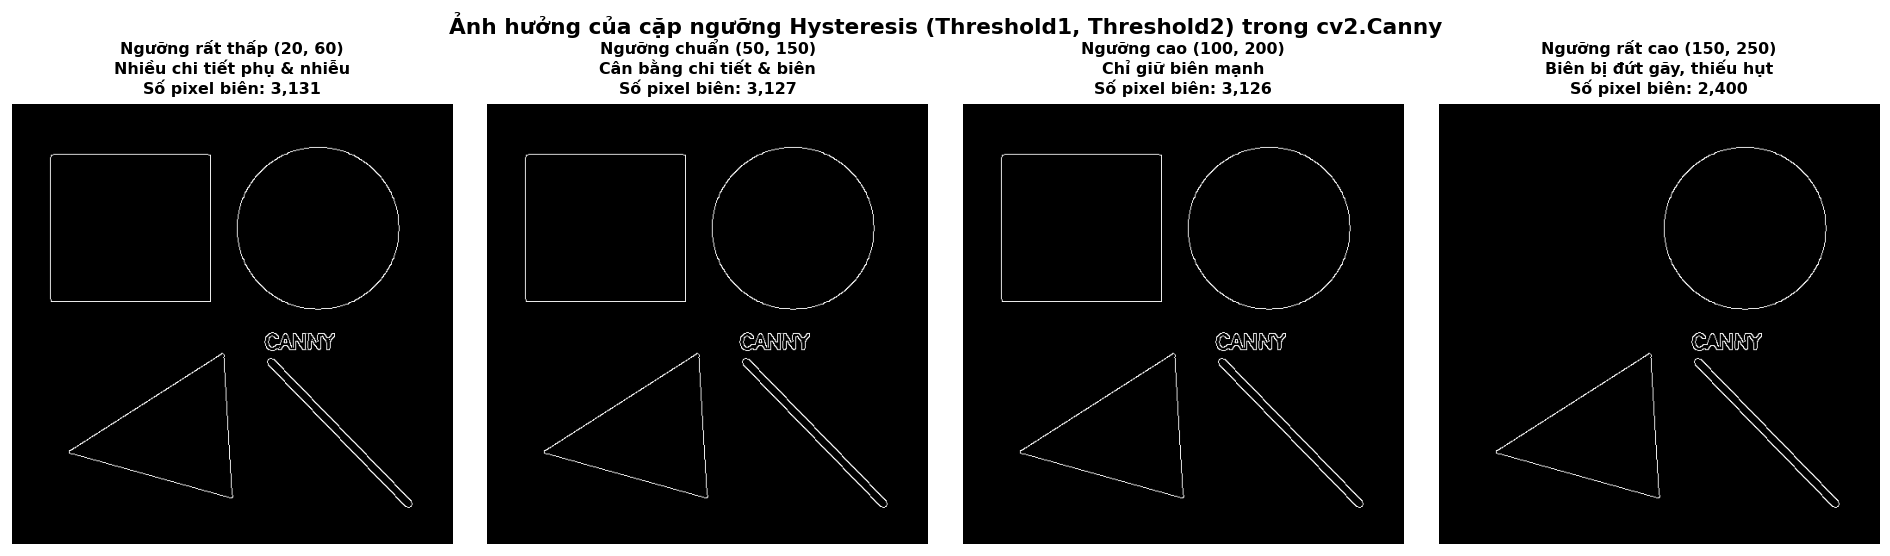

-> Đã xuất so sánh ngưỡng Hysteresis: 02_canny_threshold_comparison.png


In [4]:
# 2.1 Khảo sát các dải ngưỡng kép (threshold1, threshold2)
threshold_configs = [
    (20, 60, "Ngưỡng rất thấp (20, 60)\nNhiều chi tiết phụ & nhiễu"),
    (50, 150, "Ngưỡng chuẩn (50, 150)\nCân bằng chi tiết & biên"),
    (100, 200, "Ngưỡng cao (100, 200)\nChỉ giữ biên mạnh"),
    (150, 250, "Ngưỡng rất cao (150, 250)\nBiên bị đứt gãy, thiếu hụt")
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

for idx, (t_low, t_high, title) in enumerate(threshold_configs):
    edges = cv2.Canny(img_blur, threshold1=t_low, threshold2=t_high, apertureSize=3, L2gradient=True)
    edge_pixel_count = np.count_nonzero(edges)
    
    axes[idx].imshow(edges, cmap='gray')
    axes[idx].set_title(f"{title}\nSố pixel biên: {edge_pixel_count:,}", fontsize=9.5, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle("Ảnh hưởng của cặp ngưỡng Hysteresis (Threshold1, Threshold2) trong cv2.Canny", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

fig_path_thresh = FIGURES_DIR / "02_canny_threshold_comparison.png"
plt.savefig(fig_path_thresh, bbox_inches='tight', dpi=150)
plt.show()

print(f"-> Đã xuất so sánh ngưỡng Hysteresis: {fig_path_thresh.name}")

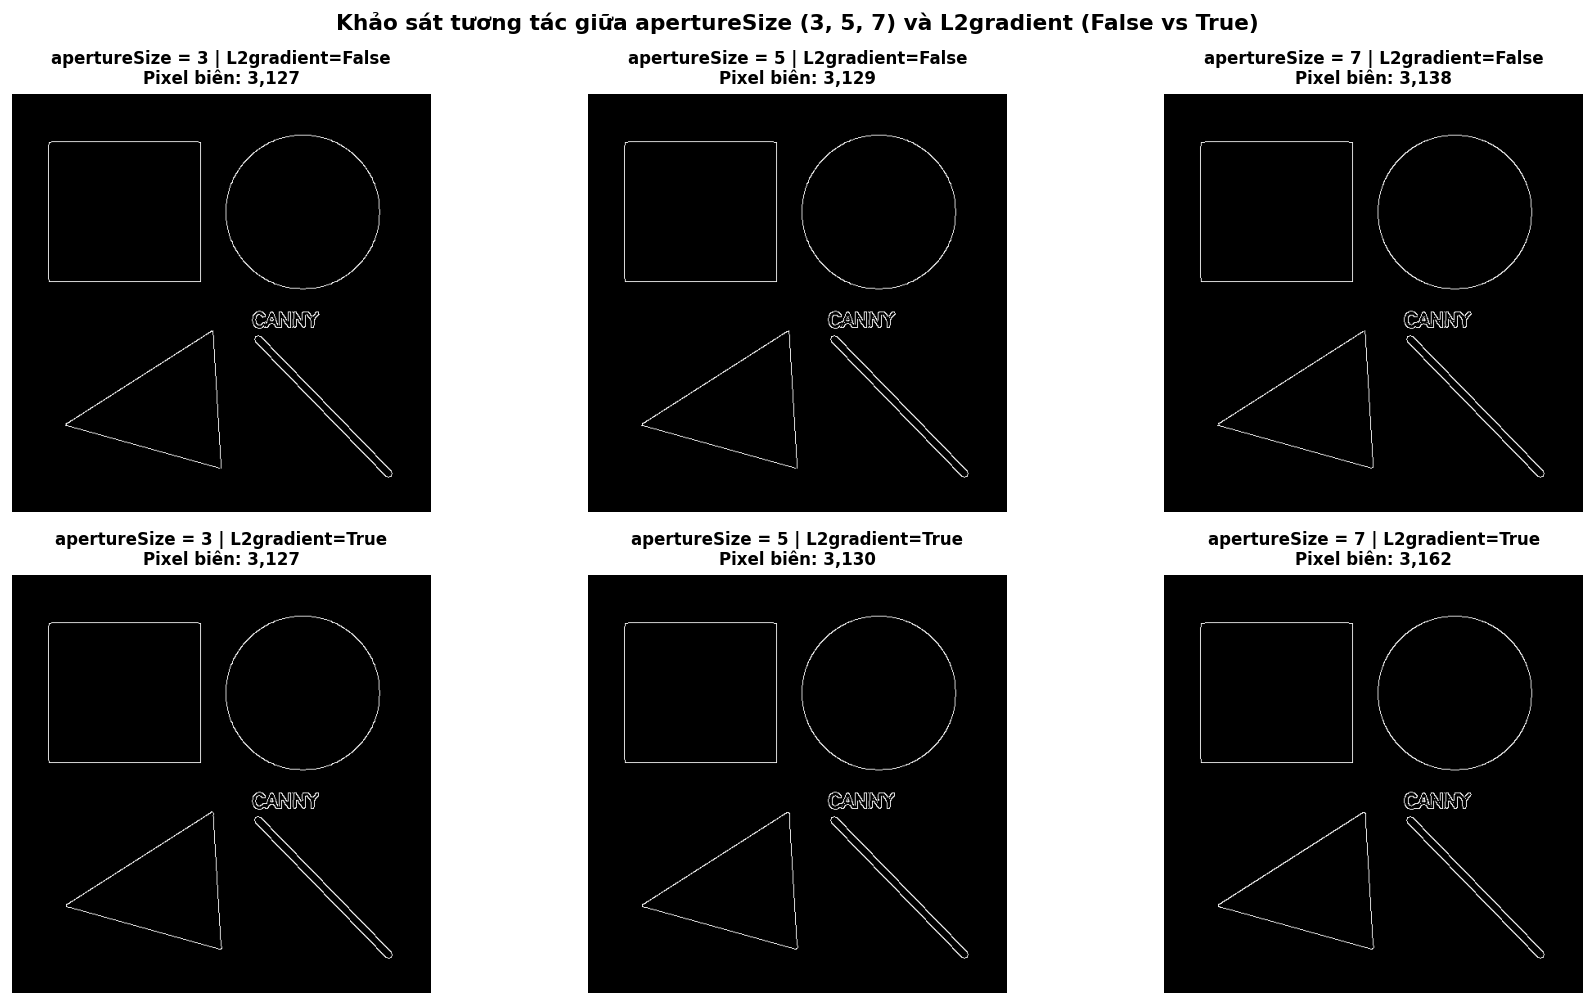

-> Đã xuất so sánh apertureSize & L2gradient: 03_canny_aperture_l2gradient.png


In [5]:
# 2.2 Khảo sát apertureSize (3, 5, 7) và L2gradient (False vs True)
aperture_list = [3, 5, 7]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))

for col, ap in enumerate(aperture_list):
    # L2gradient = False (Chuẩn L1)
    edge_l1 = cv2.Canny(img_blur, threshold1=50, threshold2=150, apertureSize=ap, L2gradient=False)
    # L2gradient = True (Chuẩn L2)
    edge_l2 = cv2.Canny(img_blur, threshold1=50, threshold2=150, apertureSize=ap, L2gradient=True)
    
    axes[0, col].imshow(edge_l1, cmap='gray')
    axes[0, col].set_title(f"apertureSize = {ap} | L2gradient=False\nPixel biên: {np.count_nonzero(edge_l1):,}", fontsize=10, fontweight='bold')
    axes[0, col].axis('off')
    
    axes[1, col].imshow(edge_l2, cmap='gray')
    axes[1, col].set_title(f"apertureSize = {ap} | L2gradient=True\nPixel biên: {np.count_nonzero(edge_l2):,}", fontsize=10, fontweight='bold')
    axes[1, col].axis('off')

plt.suptitle("Khảo sát tương tác giữa apertureSize (3, 5, 7) và L2gradient (False vs True)", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()

fig_path_aperture = FIGURES_DIR / "03_canny_aperture_l2gradient.png"
plt.savefig(fig_path_aperture, bbox_inches='tight', dpi=150)
plt.show()

print(f"-> Đã xuất so sánh apertureSize & L2gradient: {fig_path_aperture.name}")

=== ĐÁNH GIÁ ĐỊNH LƯỢNG L2GRADIENT (apertureSize=3) ===
Số pixel biên khi L2gradient=False (L1): 3,127
Số pixel biên khi L2gradient=True  (L2): 3,127
Số pixel sai khác giữa 2 phương pháp  : 74 (2.37%)


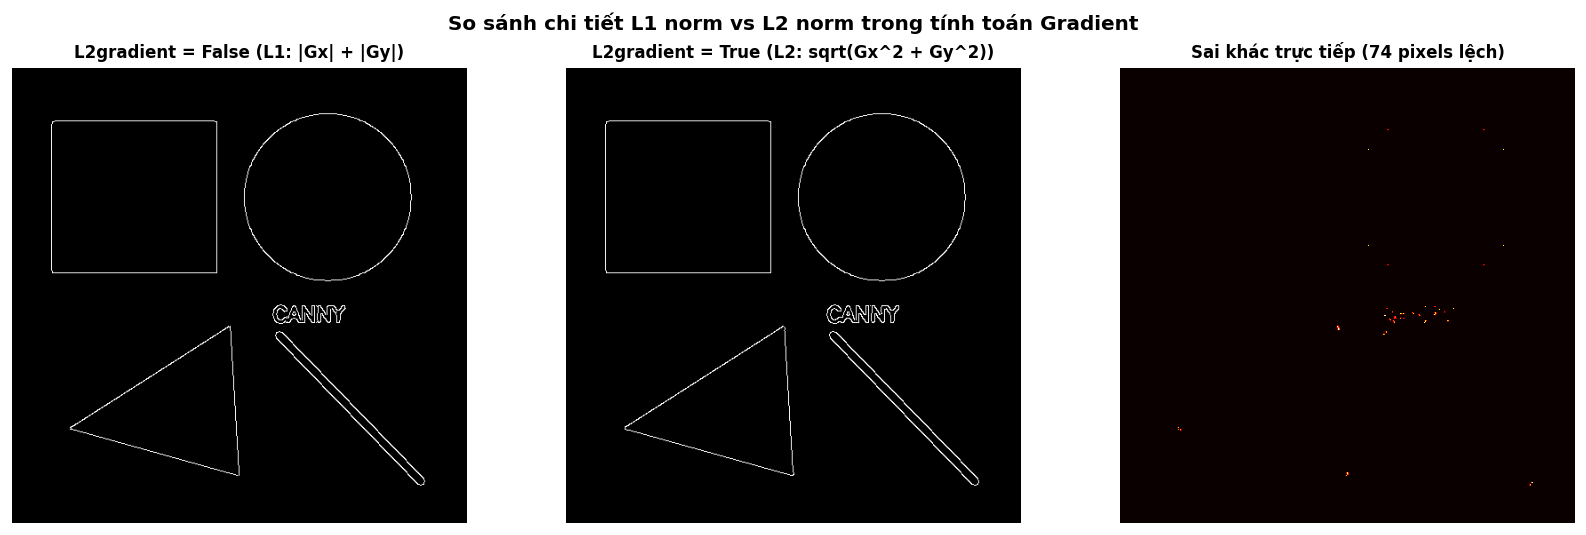

In [6]:
# 2.3 Phân tích trực tiếp độ lệch giữa L2gradient=True và L2gradient=False
edge_l1 = cv2.Canny(img_blur, threshold1=50, threshold2=150, apertureSize=3, L2gradient=False)
edge_l2 = cv2.Canny(img_blur, threshold1=50, threshold2=150, apertureSize=3, L2gradient=True)

# Ma trận sai khác pixel
diff_edges = cv2.absdiff(edge_l1, edge_l2)
num_diff_pixels = np.count_nonzero(diff_edges)
total_edge_l1 = np.count_nonzero(edge_l1)
total_edge_l2 = np.count_nonzero(edge_l2)

print("=== ĐÁNH GIÁ ĐỊNH LƯỢNG L2GRADIENT (apertureSize=3) ===")
print(f"Số pixel biên khi L2gradient=False (L1): {total_edge_l1:,}")
print(f"Số pixel biên khi L2gradient=True  (L2): {total_edge_l2:,}")
print(f"Số pixel sai khác giữa 2 phương pháp  : {num_diff_pixels:,} ({num_diff_pixels / max(total_edge_l1, 1) * 100:.2f}%)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].imshow(edge_l1, cmap='gray')
axes[0].set_title("L2gradient = False (L1: |Gx| + |Gy|)", fontsize=10, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(edge_l2, cmap='gray')
axes[1].set_title("L2gradient = True (L2: sqrt(Gx^2 + Gy^2))", fontsize=10, fontweight='bold')
axes[1].axis('off')

# Hiển thị điểm sai khác bằng màu đỏ nổi bật
axes[2].imshow(diff_edges, cmap='hot')
axes[2].set_title(f"Sai khác trực tiếp ({num_diff_pixels:,} pixels lệch)", fontsize=10, fontweight='bold')
axes[2].axis('off')

plt.suptitle("So sánh chi tiết L1 norm vs L2 norm trong tính toán Gradient", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 3. Thực hiện Canny bằng `scikit-image` (`skimage.feature.canny`)

Đặc điểm của hàm `skimage.feature.canny(image, sigma=1.0, low_threshold=None, high_threshold=None)`:
1. **Định dạng dữ liệu:**
   - Đầu vào nhận ảnh 2D grayscale (`float` trong khoảng $[0, 1]$ hoặc `uint8`).
   - Khác với OpenCV (trả về `uint8` có giá trị 0 hoặc 255), scikit-image trả về **mảng kiểu `bool`** (`True` là biên, `False` là nền).
2. **Lọc mờ tích hợp qua tham số `sigma`:**
   - scikit-image tự động tích hợp bước lọc mờ Gaussian ngay trong hàm thông qua độ lệch chuẩn `sigma` (mặc định $\sigma = 1.0$).
3. **Ngưỡng tự động:**
   - Nếu không truyền `low_threshold` và `high_threshold`, scikit-image sử dụng phương pháp thống kê (percentile hoặc Otsu) để ước lượng ngưỡng tự động.

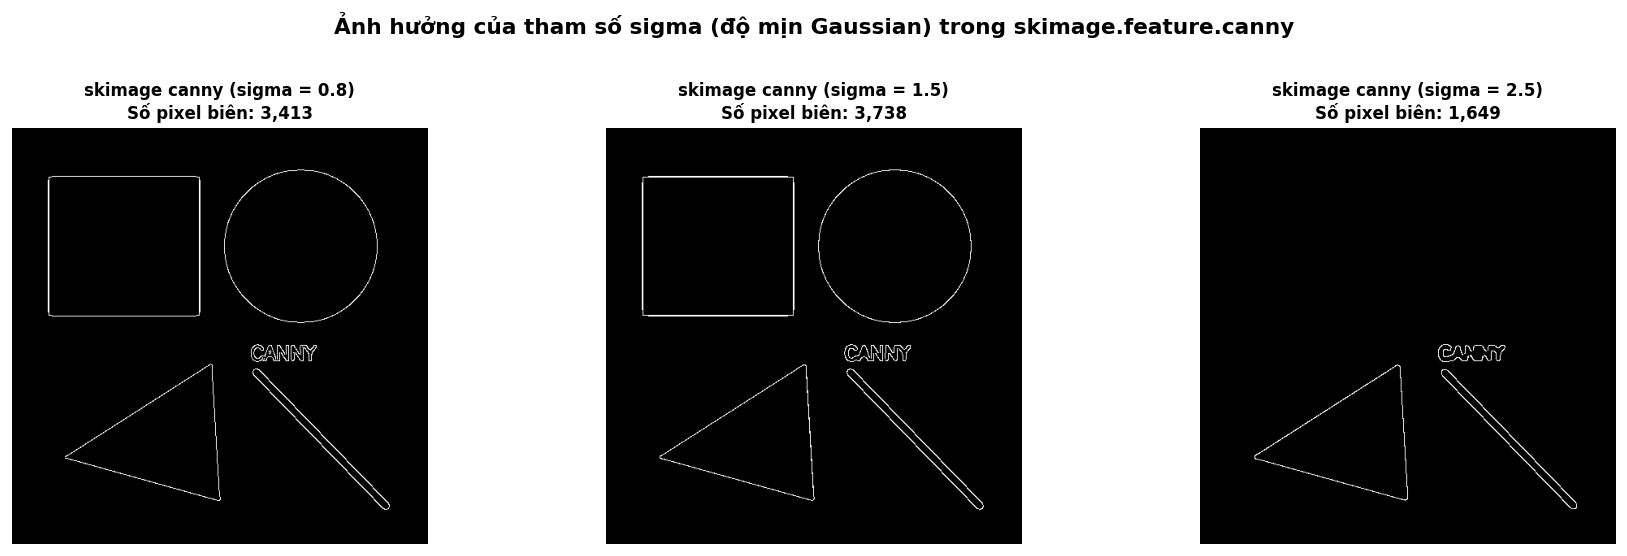

-> Đã xuất khảo sát skimage canny: 04_skimage_canny_sigma.png


In [7]:
# Chuẩn hóa ảnh sang khoảng [0, 1] dạng float cho skimage
img_gray_float = img_gray.astype(np.float64) / 255.0

# Khảo sát các giá trị sigma trong scikit-image
sigmas = [0.8, 1.5, 2.5]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, s in enumerate(sigmas):
    # low_threshold và high_threshold trên thang [0, 1] tương ứng (50/255, 150/255)
    edges_sk = canny(img_gray_float, sigma=s, low_threshold=50/255.0, high_threshold=150/255.0)
    
    axes[i].imshow(edges_sk, cmap='gray')
    axes[i].set_title(f"skimage canny (sigma = {s})\nSố pixel biên: {np.count_nonzero(edges_sk):,}", fontsize=10, fontweight='bold')
    axes[i].axis('off')

plt.suptitle("Ảnh hưởng của tham số sigma (độ mịn Gaussian) trong skimage.feature.canny", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

fig_path_skimage = FIGURES_DIR / "04_skimage_canny_sigma.png"
plt.savefig(fig_path_skimage, bbox_inches='tight', dpi=150)
plt.show()

print(f"-> Đã xuất khảo sát skimage canny: {fig_path_skimage.name}")

---
## 4. So sánh trực quan và Đánh giá hiệu năng giữa OpenCV và scikit-image

Ta tiến hành thiết lập bài toán kiểm thử đồng bộ:
- Cùng một ảnh đầu vào xám `01_hinh_hoc_ro_net.png`.
- Tương đương tham số: Làm mờ Gaussian tương đương và cặp ngưỡng tương đương (50, 150).
- Đo đạc thời gian thực thi (Benchmark) qua 50 lần chạy trung bình.

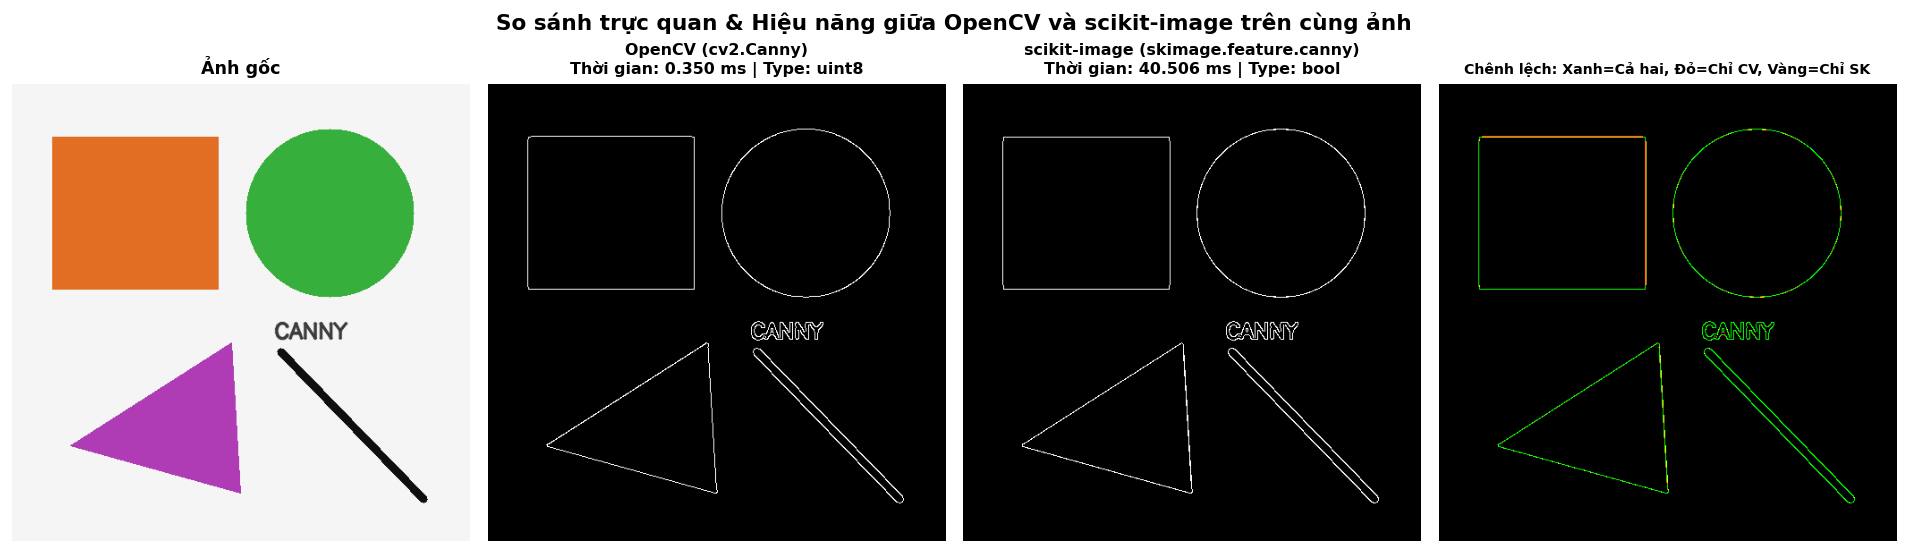

-> Đã xuất hình ảnh so sánh trực quan: 05_opencv_vs_skimage_comparison.png
-> Tốc độ OpenCV     : 0.350 ms / frame
-> Tốc độ scikit-image: 40.506 ms / frame (OpenCV nhanh hơn gấp ~115.6 lần)


In [8]:
# 1. OpenCV Canny (ảnh đã làm mờ trước bằng GaussianBlur 5x5 sigma=1.0)
img_blur_cv = cv2.GaussianBlur(img_gray, (5, 5), 1.0)
edges_opencv = cv2.Canny(img_blur_cv, threshold1=50, threshold2=150, apertureSize=3, L2gradient=True)

# 2. scikit-image Canny (dùng sigma=1.0 để tương đương, ngưỡng 50/255 và 150/255)
edges_skimage_bool = canny(img_gray_float, sigma=1.0, low_threshold=50/255.0, high_threshold=150/255.0)
edges_skimage_uint8 = np.uint8(edges_skimage_bool) * 255

# 3. Đo thời gian thực thi trung bình
N_ITERS = 50

# Đo OpenCV
t0 = time.perf_counter()
for _ in range(N_ITERS):
    _ = cv2.Canny(img_blur_cv, 50, 150, apertureSize=3, L2gradient=True)
t_opencv = (time.perf_counter() - t0) / N_ITERS * 1000  # ms

# Đo scikit-image
t0 = time.perf_counter()
for _ in range(N_ITERS):
    _ = canny(img_gray_float, sigma=1.0, low_threshold=50/255.0, high_threshold=150/255.0)
t_skimage = (time.perf_counter() - t0) / N_ITERS * 1000  # ms

# Trực quan hóa so sánh trực tiếp
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

axes[0].imshow(img_rgb)
axes[0].set_title("Ảnh gốc", fontsize=10.5, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(edges_opencv, cmap='gray')
axes[1].set_title(f"OpenCV (cv2.Canny)\nThời gian: {t_opencv:.3f} ms | Type: {edges_opencv.dtype}", fontsize=9.5, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(edges_skimage_uint8, cmap='gray')
axes[2].set_title(f"scikit-image (skimage.feature.canny)\nThời gian: {t_skimage:.3f} ms | Type: {edges_skimage_bool.dtype}", fontsize=9.5, fontweight='bold')
axes[2].axis('off')

# Mask chênh lệch (Overlay)
# Xanh lá: Cả hai cùng phát hiện
# Đỏ: Chỉ OpenCV phát hiện
# Vàng: Chỉ scikit-image phát hiện
comparison_rgb = np.zeros((*img_gray.shape, 3), dtype=np.uint8)
both_edges = (edges_opencv > 0) & edges_skimage_bool
only_cv = (edges_opencv > 0) & (~edges_skimage_bool)
only_sk = (edges_opencv == 0) & edges_skimage_bool

comparison_rgb[both_edges] = [0, 255, 0]    # Xanh lá
comparison_rgb[only_cv] = [255, 50, 50]     # Đỏ
comparison_rgb[only_sk] = [255, 255, 0]     # Vàng

axes[3].imshow(comparison_rgb)
axes[3].set_title("Chênh lệch: Xanh=Cả hai, Đỏ=Chỉ CV, Vàng=Chỉ SK", fontsize=8.5, fontweight='bold')
axes[3].axis('off')

plt.suptitle("So sánh trực quan & Hiệu năng giữa OpenCV và scikit-image trên cùng ảnh", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

fig_path_compare = FIGURES_DIR / "05_opencv_vs_skimage_comparison.png"
plt.savefig(fig_path_compare, bbox_inches='tight', dpi=150)
plt.show()

print(f"-> Đã xuất hình ảnh so sánh trực quan: {fig_path_compare.name}")
print(f"-> Tốc độ OpenCV     : {t_opencv:.3f} ms / frame")
print(f"-> Tốc độ scikit-image: {t_skimage:.3f} ms / frame (OpenCV nhanh hơn gấp ~{t_skimage/t_opencv:.1f} lần)")

---
## 5. Thử nghiệm trên ảnh thực tế nhiều chi tiết (`04_anh_that_nhieu_chi_tiet.png`)

Để chứng minh tính tổng quát của phân tích, ta áp dụng thuật toán Canny của cả hai thư viện lên ảnh chụp thực tế có độ tương phản và chi tiết phức tạp cao.

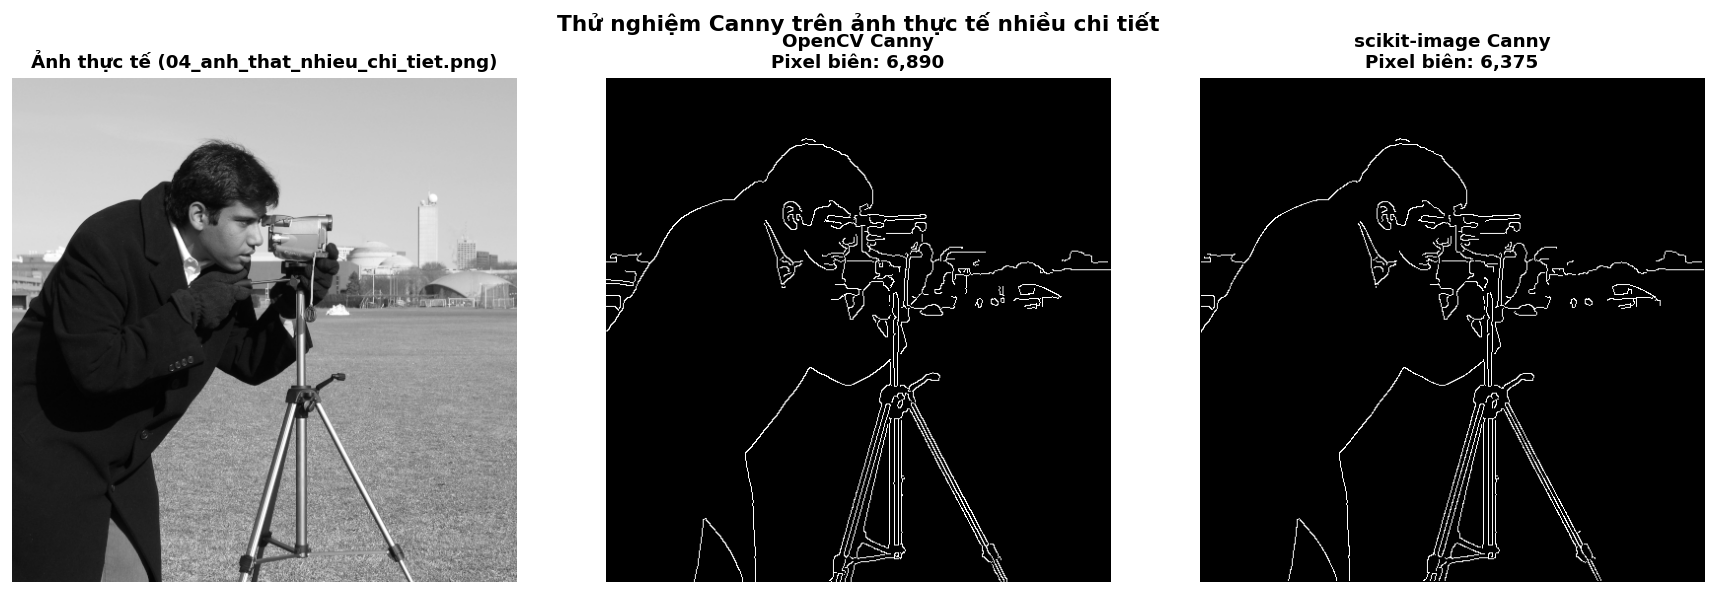

-> Đã xuất biểu đồ ảnh phức tạp: 06_complex_image_canny.png
-> Đã lưu các ảnh kết quả biên vào: output


In [9]:
complex_img_path = INPUT_DIR / "04_anh_that_nhieu_chi_tiet.png"
if not complex_img_path.exists():
    complex_img_path = list(INPUT_DIR.glob("*.png"))[1]

img_complex_bgr = read_image_bgr(complex_img_path)
img_complex_rgb = cv2.cvtColor(img_complex_bgr, cv2.COLOR_BGR2RGB)
img_complex_gray = cv2.cvtColor(img_complex_bgr, cv2.COLOR_BGR2GRAY)
img_complex_float = img_complex_gray.astype(np.float64) / 255.0

# OpenCV Canny
img_complex_blur = cv2.GaussianBlur(img_complex_gray, (5, 5), 1.2)
edges_complex_cv = cv2.Canny(img_complex_blur, 60, 160, apertureSize=3, L2gradient=True)

# scikit-image Canny
edges_complex_sk = canny(img_complex_float, sigma=1.2, low_threshold=60/255.0, high_threshold=160/255.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_complex_rgb)
axes[0].set_title(f"Ảnh thực tế ({complex_img_path.name})", fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(edges_complex_cv, cmap='gray')
axes[1].set_title(f"OpenCV Canny\nPixel biên: {np.count_nonzero(edges_complex_cv):,}", fontsize=11, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(edges_complex_sk, cmap='gray')
axes[2].set_title(f"scikit-image Canny\nPixel biên: {np.count_nonzero(edges_complex_sk):,}", fontsize=11, fontweight='bold')
axes[2].axis('off')

plt.suptitle("Thử nghiệm Canny trên ảnh thực tế nhiều chi tiết", fontsize=13, fontweight='bold')
plt.tight_layout()

fig_path_complex = FIGURES_DIR / "06_complex_image_canny.png"
plt.savefig(fig_path_complex, bbox_inches='tight', dpi=150)
plt.show()

# Lưu ảnh kết quả vào data/output
save_image(OUTPUT_DIR / "01_canny_opencv_sample.png", edges_opencv)
save_image(OUTPUT_DIR / "01_canny_skimage_sample.png", edges_skimage_uint8)
save_image(OUTPUT_DIR / "01_canny_complex_cv.png", edges_complex_cv)

print(f"-> Đã xuất biểu đồ ảnh phức tạp: {fig_path_complex.name}")
print(f"-> Đã lưu các ảnh kết quả biên vào: {OUTPUT_DIR.name}")

---
## 6. Bảng tổng kết so sánh & Kết luận phân tích

### Bảng đối sánh kỹ thuật giữa OpenCV và scikit-image:

| Tiêu chí so sánh | OpenCV (`cv2.Canny`) | scikit-image (`skimage.feature.canny`) |
| :--- | :--- | :--- |
| **Ngôn ngữ lõi** | C / C++ tối ưu hóa SIMD & GPU | Python / Cython |
| **Kiểu dữ liệu đầu vào** | `np.uint8` (thang giá trị $[0, 255]$) | `np.float64` / `np.float32` ($[0, 1]$) hoặc `uint8` |
| **Kiểu dữ liệu đầu ra** | `np.uint8` (chỉ chứa 2 mức: $0$ và $255$) | `numpy.bool_` (`True` và `False`) |
| **Tích hợp làm mờ** | Người dùng thường chủ động tiền xử lý bằng `cv2.GaussianBlur` | Tự động tích hợp sẵn bộ lọc Gaussian qua tham số `sigma` |
| **Khẩu độ Sobel** | Tùy biến linh hoạt qua `apertureSize` (3, 5, 7) | Cố định theo thuật toán tích chập đạo hàm Gaussian |
| **L2gradient** | Cho phép chọn giữa chuẩn $L_1$ và chuẩn $L_2$ | Chuẩn $L_2$ chính xác mặc định |
| **Tốc độ xử lý** | **Cực nhanh** (thích hợp cho bài toán thời gian thực, camera, video stream) | **Chậm hơn** (~10–30 lần), thích hợp cho nghiên cứu, khoa học dữ liệu |
| **Tính ứng dụng** | Hệ thống nhúng, xe tự hành, camera giám sát | Xử lý ảnh y tế, ảnh sinh học, nghiên cứu thực nghiệm |

---

### ✅ Kết luận rút ra từ bài thực hành:
1. **Các bước trung gian:** Việc khử nhiễu trước khi tính gradient là bước sống còn. Không làm mờ sẽ khiến Canny bắt rất nhiều cạnh nhiễu không mong muốn.
2. **Cặp ngưỡng Hysteresis:** Tỷ lệ $T_{high} / T_{low} \approx 2:1$ hoặc $3:1$ đem lại hiệu quả tốt nhất. Nếu tăng ngưỡng quá cao sẽ làm đứt đoạn các biên yếu; nếu hạ quá thấp sẽ giữ lại nhiễu nền.
3. **`apertureSize`:** `ksize=3` là lựa chọn chuẩn xác nhất cho ảnh thông thường. Tăng lên 5 hoặc 7 chỉ hữu ích khi ảnh bị nhiễu hạt nặng hoặc muốn phát hiện biên quy mô lớn.
4. **`L2gradient`:** Việc kích hoạt `L2gradient=True` giúp đường biên mượt mà và đúng hình học hơn, đặc biệt ở các góc chéo, với chi phí tính toán tăng không đáng kể trên các CPU hiện đại.